In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)



In [16]:
df = pd.read_csv("Dataset\Training.csv")
print("Shape:", df.shape)
df.head()



Shape: (4920, 133)


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection


In [17]:
print(df.info())
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Number of diseases:", df["prognosis"].nunique())
print("Number of symptoms:", df.shape[1] - 1)



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4920 entries, 0 to 4919
Columns: 133 entries, itching to prognosis
dtypes: int64(132), object(1)
memory usage: 5.0+ MB
None

Missing values: 0
Duplicate rows: 4616
Number of diseases: 41
Number of symptoms: 132


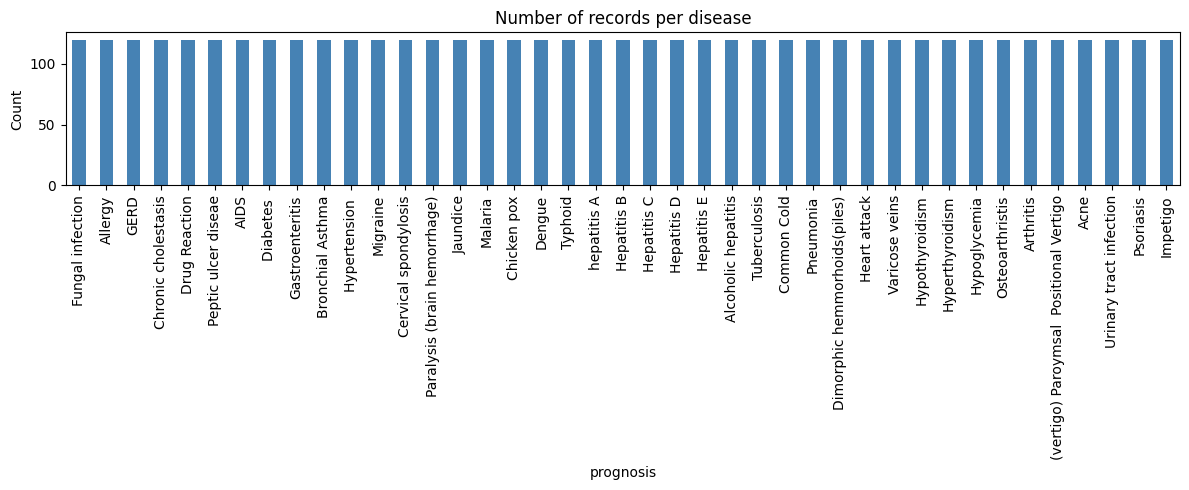

In [18]:
plt.figure(figsize=(12, 5))
df["prognosis"].value_counts().plot(kind="bar", color="steelblue")
plt.title("Number of records per disease")
plt.ylabel("Count")
plt.tight_layout()
plt.show()



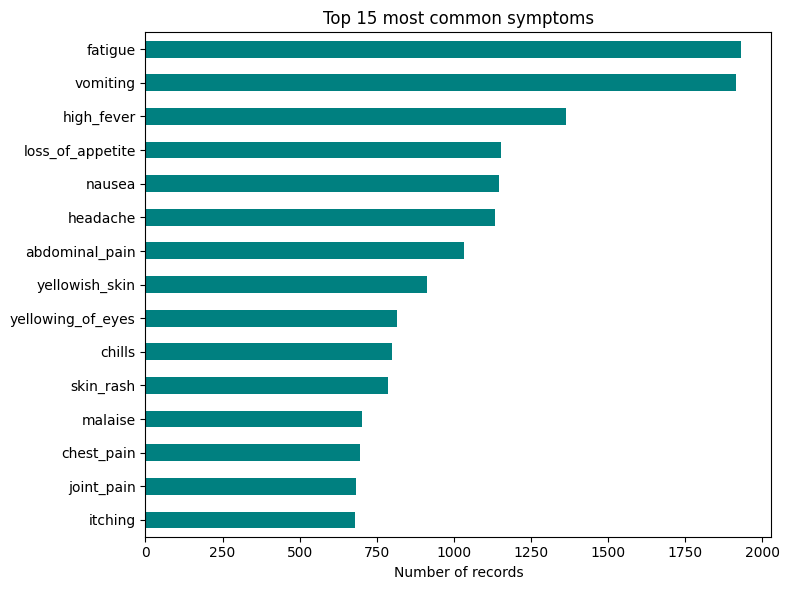

Least common symptoms:
dischromic _patches    108
scurring               108
pus_filled_pimples     108
foul_smell_of urine    102
fluid_overload           0
dtype: int64


In [19]:
symptom_counts = df.drop("prognosis", axis=1).sum().sort_values(ascending=False)

plt.figure(figsize=(8, 6))
symptom_counts.head(15).plot(kind="barh", color="teal")
plt.gca().invert_yaxis()
plt.title("Top 15 most common symptoms")
plt.xlabel("Number of records")
plt.tight_layout()
plt.show()

print("Least common symptoms:")
print(symptom_counts.tail(5))



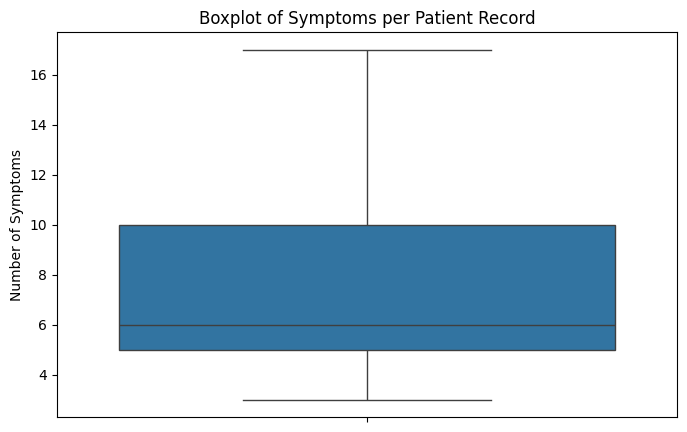

In [20]:
df["symptom_count"] = df.drop("prognosis", axis=1).sum(axis=1)

plt.figure(figsize=(8, 5))
sns.boxplot(y=df["symptom_count"])
plt.title("Boxplot of Symptoms per Patient Record")
plt.ylabel("Number of Symptoms")
plt.show()

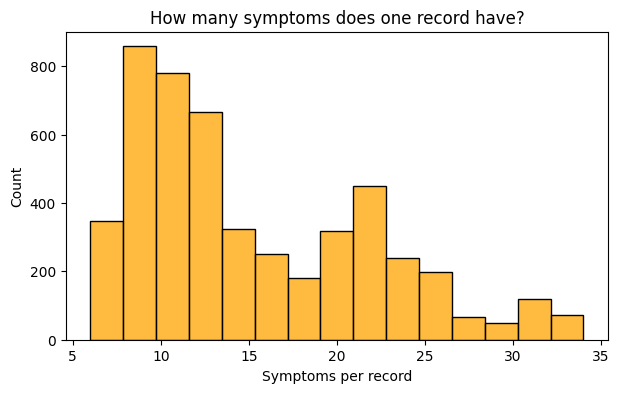

count    4920.000000
mean       14.897561
std         7.184332
min         6.000000
25%        10.000000
50%        12.000000
75%        20.000000
max        34.000000
Name: symptom_count, dtype: float64


In [21]:
df["symptom_count"] = df.drop("prognosis", axis=1).sum(axis=1)
plt.figure(figsize=(7, 4))
sns.histplot(df["symptom_count"], bins=15, color="orange")
plt.title("How many symptoms does one record have?")
plt.xlabel("Symptoms per record")
plt.show()
print(df["symptom_count"].describe())
df = df.drop("symptom_count", axis=1)



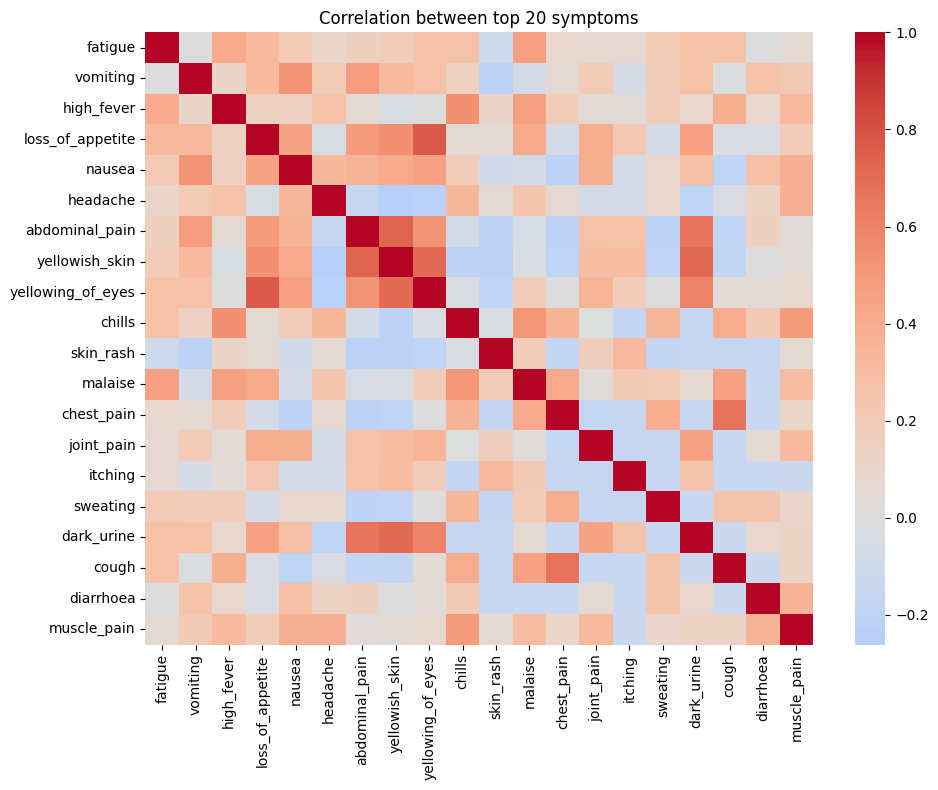

In [22]:
top20 = symptom_counts.head(20).index
plt.figure(figsize=(10, 8))
sns.heatmap(df[top20].corr(), cmap="coolwarm", center=0)
plt.title("Correlation between top 20 symptoms")
plt.tight_layout()
plt.show()



In [23]:
for disease in ["Diabetes ", "Malaria", "Typhoid"]:
    sub = df[df["prognosis"] == disease].drop("prognosis", axis=1)
    if len(sub) == 0:
        continue
    top = sub.mean().sort_values(ascending=False).head(6)
    print(f"\n{disease.strip()} - most frequent symptoms:")
    print(top.round(2))




Diabetes - most frequent symptoms:
increased_appetite    1.00
polyuria              1.00
fatigue               0.95
weight_loss           0.95
obesity               0.95
excessive_hunger      0.95
dtype: float64

Malaria - most frequent symptoms:
muscle_pain    1.00
vomiting       0.95
chills         0.95
nausea         0.95
sweating       0.95
headache       0.95
dtype: float64

Typhoid - most frequent symptoms:
fatigue                1.00
high_fever             1.00
chills                 1.00
vomiting               0.95
diarrhoea              0.95
toxic_look_(typhos)    0.95
dtype: float64


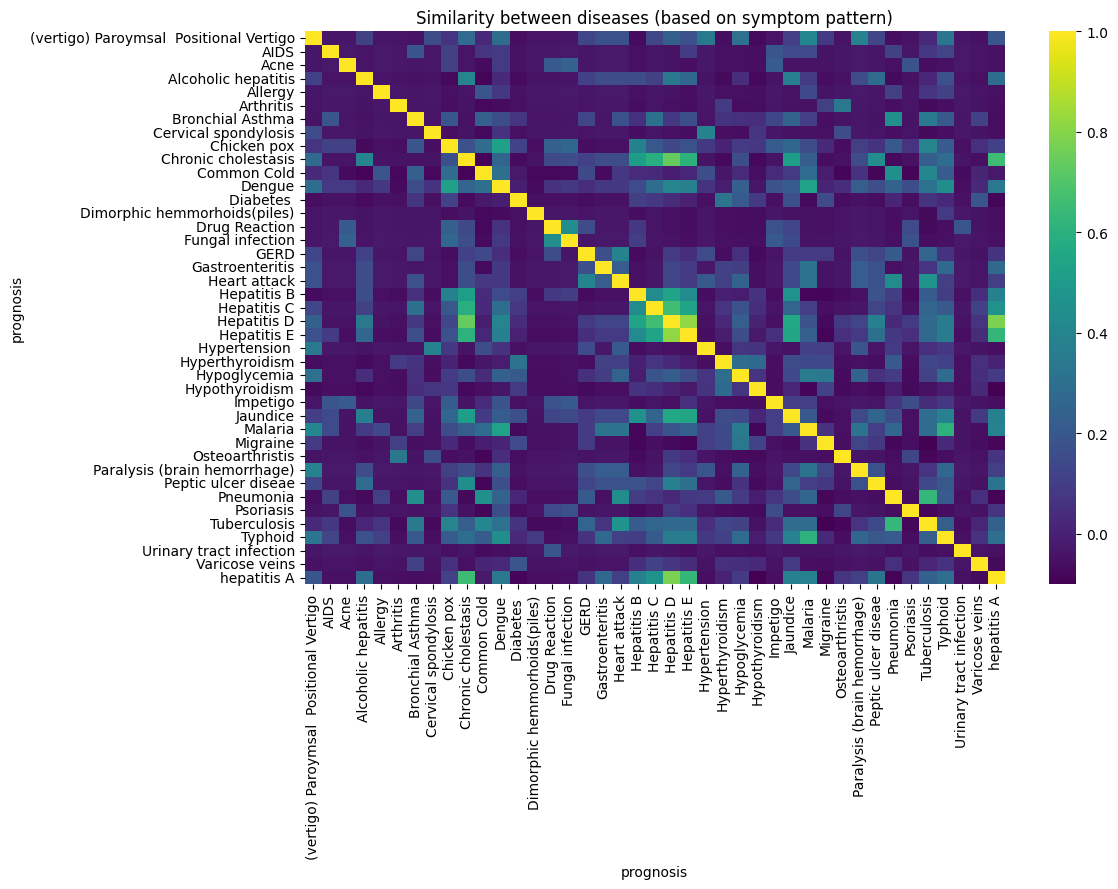

In [24]:
avg = df.groupby("prognosis").mean()
plt.figure(figsize=(12, 9))
sns.heatmap(avg.T.corr(), cmap="viridis")
plt.title("Similarity between diseases (based on symptom pattern)")
plt.tight_layout()
plt.show()



                Symptom  weight
0               itching       1
1             skin_rash       3
2  nodal_skin_eruptions       4
3   continuous_sneezing       4
4             shivering       5


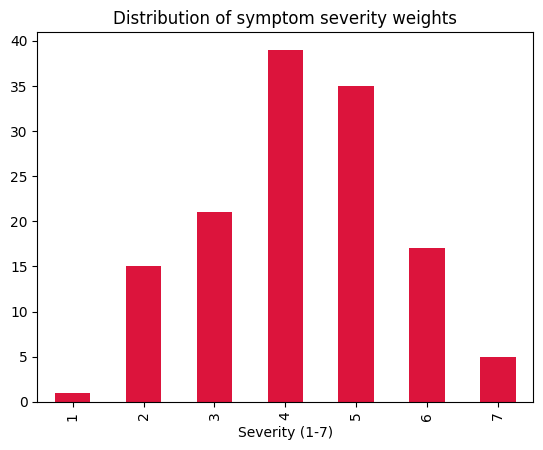

In [25]:
sev = pd.read_csv("Dataset\Symptom-severity.csv")
print(sev.head())
sev.iloc[:, 1].value_counts().sort_index().plot(kind="bar", color="crimson")
plt.title("Distribution of symptom severity weights")
plt.xlabel("Severity (1-7)")
plt.show()



In [26]:
X = df.drop("prognosis", axis=1)
le = LabelEncoder()
y = le.fit_transform(df["prognosis"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)



Train: (3936, 132)  Test: (984, 132)


In [27]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Naive Bayes": BernoulliNB(),
    "SVM": SVC(kernel="linear", probability=True),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=50, random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1": f1_score(y_test, pred, average="weighted", zero_division=0),
    })

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
print(results_df.round(4).to_string(index=False))



              Model  Accuracy  Precision  Recall  F1
Logistic Regression       1.0        1.0     1.0 1.0
      Decision Tree       1.0        1.0     1.0 1.0
      Random Forest       1.0        1.0     1.0 1.0
        Naive Bayes       1.0        1.0     1.0 1.0
                SVM       1.0        1.0     1.0 1.0
                KNN       1.0        1.0     1.0 1.0
  Gradient Boosting       1.0        1.0     1.0 1.0


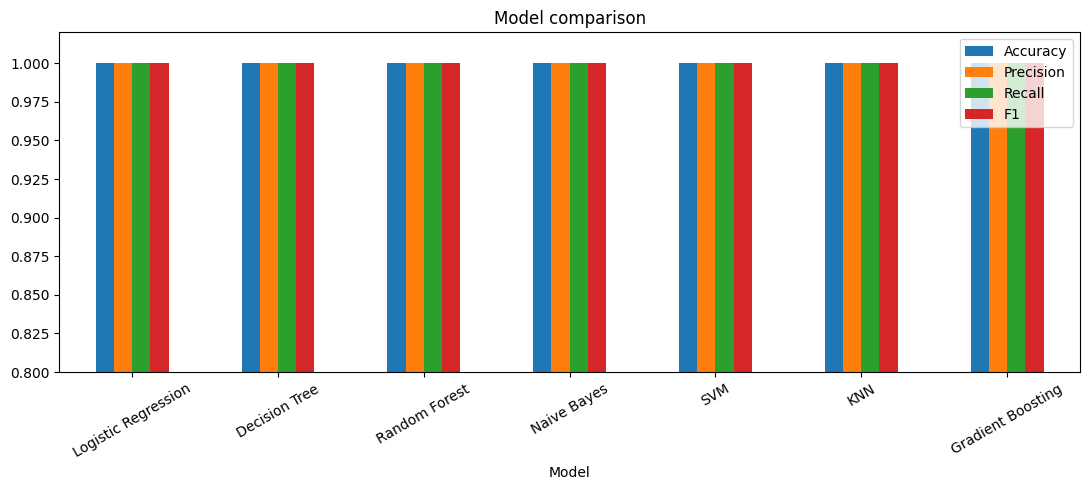

In [28]:
results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(11, 5))
plt.title("Model comparison")
plt.ylim(0.8, 1.02)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



In [29]:
cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5)
    cv_rows.append({"Model": name, "CV Mean": scores.mean(), "CV Std": scores.std()})
print(pd.DataFrame(cv_rows).round(4).to_string(index=False))



              Model  CV Mean  CV Std
Logistic Regression      1.0     0.0
      Decision Tree      1.0     0.0
      Random Forest      1.0     0.0
        Naive Bayes      1.0     0.0
                SVM      1.0     0.0
                KNN      1.0     0.0
  Gradient Boosting      1.0     0.0


Best model: Logistic Regression


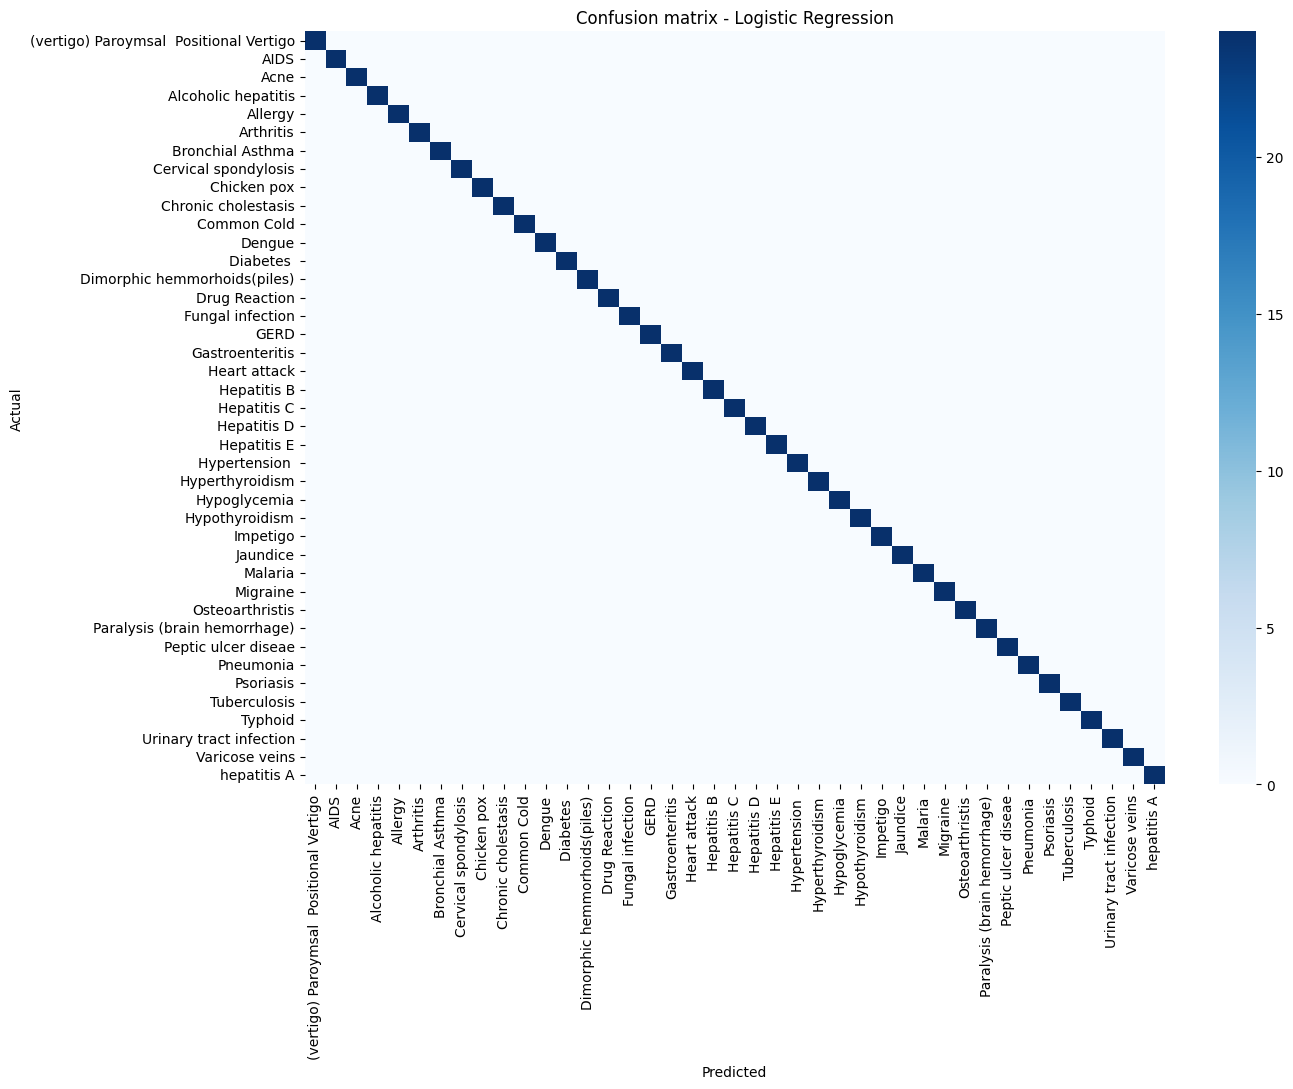

                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00        24
                                   AIDS       1.00      1.00      1.00        24
                                   Acne       1.00      1.00      1.00        24
                    Alcoholic hepatitis       1.00      1.00      1.00        24
                                Allergy       1.00      1.00      1.00        24
                              Arthritis       1.00      1.00      1.00        24
                       Bronchial Asthma       1.00      1.00      1.00        24
                   Cervical spondylosis       1.00      1.00      1.00        24
                            Chicken pox       1.00      1.00      1.00        24
                    Chronic cholestasis       1.00      1.00      1.00        24
                            Common Cold       1.00      1.00      1.00        24
                           

In [30]:
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]
y_pred = best_model.predict(X_test)
print("Best model:", best_name)

plt.figure(figsize=(14, 11))
sns.heatmap(confusion_matrix(y_test, y_pred), cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"Confusion matrix - {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))



In [31]:
proba = best_model.predict_proba(X_test)
top3 = np.argsort(proba, axis=1)[:, -3:]
top3_acc = np.mean([y_test[i] in top3[i] for i in range(len(y_test))])
print("Top-3 accuracy:", round(top3_acc, 4))



Top-3 accuracy: 1.0


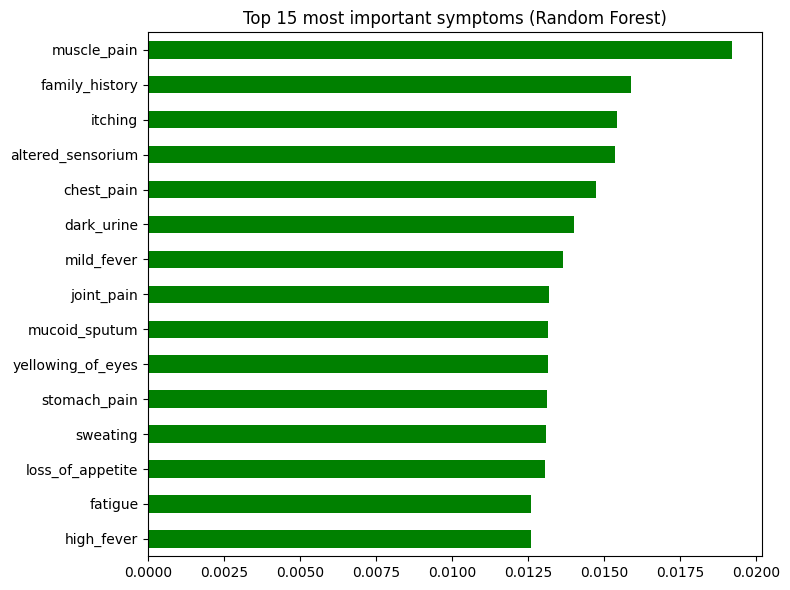

In [32]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 6))
imp.head(15).plot(kind="barh", color="green")
plt.gca().invert_yaxis()
plt.title("Top 15 most important symptoms (Random Forest)")
plt.tight_layout()
plt.show()



In [33]:
for name, model in models.items():
    tr = accuracy_score(y_train, model.predict(X_train))
    te = accuracy_score(y_test, model.predict(X_test))
    print(f"{name:20s} train={tr:.3f}  test={te:.3f}")



Logistic Regression  train=1.000  test=1.000


Decision Tree        train=1.000  test=1.000
Random Forest        train=1.000  test=1.000
Naive Bayes          train=1.000  test=1.000
SVM                  train=1.000  test=1.000
KNN                  train=1.000  test=1.000
Gradient Boosting    train=1.000  test=1.000


In [34]:
joblib.dump(best_model, "best_model.pkl")
joblib.dump(le, "label_encoder.pkl")
joblib.dump(list(X.columns), "symptom_list.pkl")
print("Saved model files")



Saved model files


In [36]:
desc = pd.read_csv("Dataset/description.csv")
prec = pd.read_csv("Dataset/precautions_df.csv")
med = pd.read_csv("Dataset/medications.csv")
diet = pd.read_csv("Dataset/diets.csv")
work = pd.read_csv("Dataset/workout_df.csv")

# make the disease column name the same in every file
for d in (desc, prec, med, diet, work):
    d.columns = [c.strip().lower() for c in d.columns]

def get_info(disease):
    disease = disease.strip()
    def find(d):
        return d[d["disease"].str.strip().str.lower() == disease.lower()]
    info = {}
    info["Description"] = " ".join(find(desc)["description"].astype(str))
    p = find(prec)
    info["Precautions"] = [str(v) for v in p.iloc[:, 1:].values.flatten() if str(v) != "nan"]
    info["Medications"] = list(find(med)["medication"].astype(str))
    info["Diet"] = list(find(diet)["diet"].astype(str))
    info["Workout"] = list(find(work)["workout"].astype(str))
    return info



In [37]:
def predict_disease(symptoms):
    row = pd.DataFrame(np.zeros((1, len(X.columns))), columns=X.columns)
    for s in symptoms:
        s = s.strip().lower().replace(" ", "_")
        if s in row.columns:
            row[s] = 1
        else:
            print("Unknown symptom ignored:", s)
    p = best_model.predict_proba(row)[0]
    top = np.argsort(p)[-3:][::-1]
    print("Top 3 predictions:")
    for i in top:
        print(f"  {le.classes_[i]:30s} {p[i]*100:.1f}%")
    info = get_info(le.classes_[top[0]])
    print("\nPredicted disease:", le.classes_[top[0]])
    for k, v in info.items():
        print(f"{k}: {v}")
    print("\nDISCLAIMER: Educational project only, not medical advice.")

predict_disease(["itching", "skin_rash", "nodal_skin_eruptions"])


Top 3 predictions:
  Fungal infection               88.9%
  Drug Reaction                  3.0%
  Acne                           1.1%

Predicted disease: Fungal infection
Description: Fungal infection is a common skin condition caused by fungi.
Precautions: ['Fungal infection', 'bath twice', 'use detol or neem in bathing water', 'keep infected area dry', 'use clean cloths']
Medications: ["['Antifungal Cream', 'Fluconazole', 'Terbinafine', 'Clotrimazole', 'Ketoconazole']"]
Diet: ["['Antifungal Diet', 'Probiotics', 'Garlic', 'Coconut oil', 'Turmeric']"]
Workout: ['Avoid sugary foods', 'Consume probiotics', 'Increase intake of garlic', 'Include yogurt in diet', 'Limit processed foods', 'Stay hydrated', 'Consume green tea', 'Eat foods rich in zinc', 'Include turmeric in diet', 'Eat fruits and vegetables']

DISCLAIMER: Educational project only, not medical advice.


===== TEST RESULTS =====
Accuracy : 0.7
Precision: 0.7519
Recall   : 0.7
F1 Score : 0.7011

===== CLASSIFICATION REPORT =====
                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00         2
                                   AIDS       1.00      1.00      1.00         1
                                   Acne       0.67      1.00      0.80         2
                    Alcoholic hepatitis       0.00      0.00      0.00         1
                                Allergy       0.75      0.75      0.75         4
                              Arthritis       0.00      0.00      0.00         1
                       Bronchial Asthma       0.75      0.75      0.75         4
                   Cervical spondylosis       0.50      0.50      0.50         2
                            Chicken pox       1.00      1.00      1.00         5
                    Chronic cholestasis       0.50      1.00   

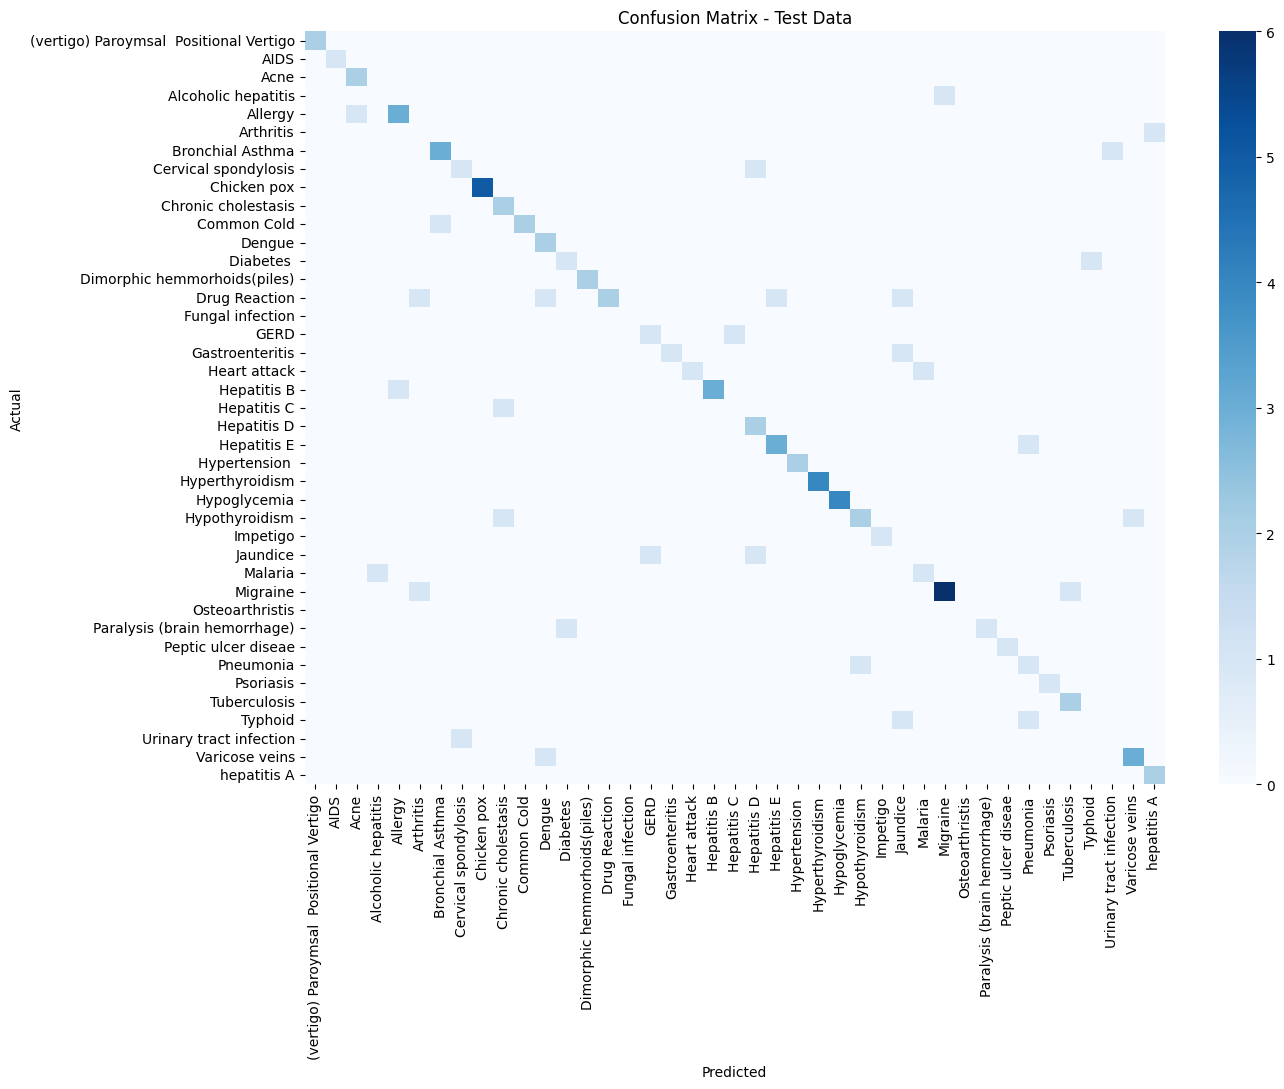


===== ACTUAL VS PREDICTED =====
                         Actual Disease                       Predicted Disease
                            Hepatitis E                             Hepatitis E
                            Hepatitis B                             Hepatitis B
                            Chicken pox                             Chicken pox
                        Hyperthyroidism                         Hyperthyroidism
                       Bronchial Asthma                        Bronchial Asthma
                                Allergy                                 Allergy
                         Varicose veins                                  Dengue
                                   GERD                             Hepatitis C
                            Hepatitis D                             Hepatitis D
                    Peptic ulcer diseae                     Peptic ulcer diseae
                                Allergy                                 Allergy
       

In [38]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Load trained model
model = joblib.load("best_model.pkl")

# Load label encoder
le = joblib.load("label_encoder.pkl")

# Load symptom list
symptom_list = joblib.load("symptom_list.pkl")

# Load test data
test_df = pd.read_csv("disease_prediction_100_stress_test.csv")

# Separate input and actual output
X_test = test_df[symptom_list]
y_test = le.transform(test_df["prognosis"])

# Predict
y_pred = model.predict(X_test)

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print("===== TEST RESULTS =====")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

# Classification report
print("\n===== CLASSIFICATION REPORT =====")

all_labels = range(len(le.classes_))

print(classification_report(
    y_test,
    y_pred,
    labels=all_labels,
    target_names=le.classes_,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=all_labels
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title("Confusion Matrix - Test Data")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Actual vs Predicted
results = pd.DataFrame({
    "Actual Disease": le.inverse_transform(y_test),
    "Predicted Disease": le.inverse_transform(y_pred)
})

print("\n===== ACTUAL VS PREDICTED =====")
print(results.to_string(index=False))